In [ ]:
!pip -q install -U transformers accelerate scikit-learn pandas \
    matplotlib seaborn joblib

In [ ]:
import pandas as pd
import numpy as np
import os
import random
import json
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

df = pd.read_csv("warangal_mental_health.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["label_name"].value_counts())

print("\nLabel mapping:")
print(df.groupby(["label", "label_name"]).size())

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Dataset shape: (1500, 3)
Columns: ['text', 'label', 'label_name']


,text,label,label_name
0,this morning anyone have notes for machine lea...,0,normal
1,"Naku em chesina point ledu anipisthundi, life ...",1,depression
2,tonight Subedari daggara new biryani place try...,0,normal
3,"Idi evarikee cheppaledu, depression tho strugg...",1,depression
4,"Honestly, comment section lo andaru mental fel...",2,toxic



Missing values:
text          0
label         0
label_name    0
dtype: int64

Class distribution:
label_name
normal        500
depression    500
toxic         500
Name: count, dtype: int64

Label mapping:
label  label_name
0      normal        500
1      depression    500
2      toxic         500
dtype: int64


Duplicate rows: 0
Duplicate texts: 0


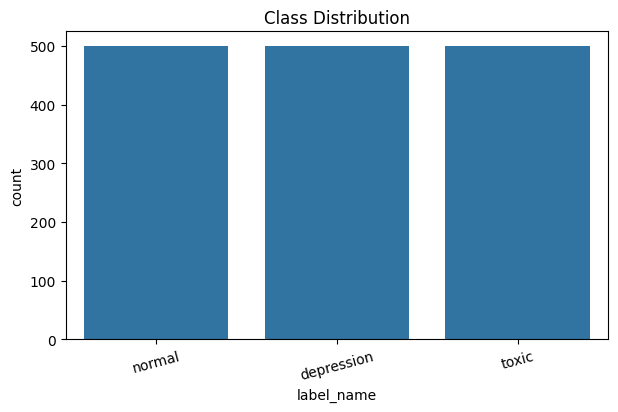

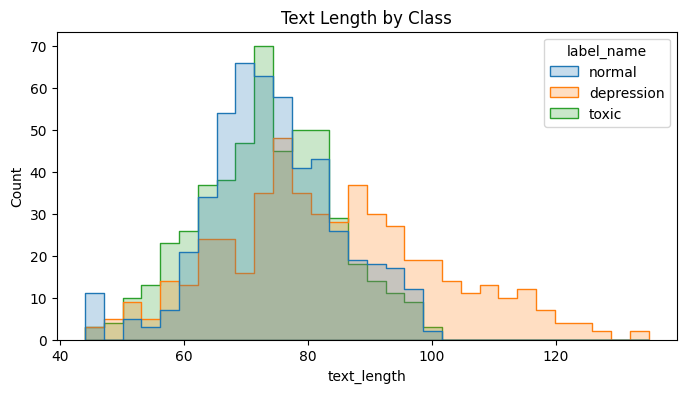

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate texts:", df["text"].duplicated().sum())

df["text_length"] = df["text"].astype(str).str.len()

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="label_name")
plt.title("Class Distribution")
plt.xticks(rotation=15)
plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="text_length", hue="label_name",
             bins=30, element="step")
plt.title("Text Length by Class")
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split

df = df[["text", "label", "label_name"]].copy()

df["text"] = df["text"].fillna("").astype(str).str.strip()
df = df[df["text"] != ""].copy()

# Ensure the supplied numeric labels agree with their class names.
label_names = sorted(df["label_name"].unique())
label2id = {name: i for i, name in enumerate(label_names)}
id2label = {i: name for name, i in label2id.items()}

assert all(
    df.groupby("label_name")["label"].nunique() == 1
), "A class name maps to multiple numeric labels."

df["label"] = df["label_name"].map(label2id).astype(int)

# Exact duplicate text with conflicting labels needs investigation.
conflicts = df.groupby("text")["label"].nunique()
conflicts = conflicts[conflicts > 1]
print("Texts with conflicting labels:", len(conflicts))

if len(conflicts):
    display(df[df["text"].isin(conflicts.index)].sort_values("text").head(20))
    raise ValueError(
        "Resolve conflicting duplicate texts before training."
    )

# Keep one copy of exact duplicate examples.
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTraining distribution:")
print(train_df["label_name"].value_counts(normalize=True))

print("\nValidation distribution:")
print(val_df["label_name"].value_counts(normalize=True))

print("\nTest distribution:")
print(test_df["label_name"].value_counts(normalize=True))

Texts with conflicting labels: 0
Train: (1050, 3)
Validation: (225, 3)
Test: (225, 3)

Training distribution:
label_name
depression    0.333333
normal        0.333333
toxic         0.333333
Name: proportion, dtype: float64

Validation distribution:
label_name
toxic         0.333333
normal        0.333333
depression    0.333333
Name: proportion, dtype: float64

Test distribution:
label_name
normal        0.333333
toxic         0.333333
depression    0.333333
Name: proportion, dtype: float64


In [ ]:
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import joblib

X_train = train_df["text"]
y_train = train_df["label"]

X_val = val_df["text"]
y_val = val_df["label"]

X_test = test_df["text"]
y_test = test_df["label"]

tfidf = FeatureUnion([
    ("word", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=1,
        max_features=50000,
        sublinear_tf=True
    )),
    ("char", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        min_df=1,
        max_features=50000,
        sublinear_tf=True
    ))
])

baseline_models = {
    "TFIDF_LogisticRegression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    ),
    "TFIDF_LinearSVM": LinearSVC(
        class_weight="balanced",
        random_state=SEED
    )
}

baseline_results = []
fitted_baselines = {}

for name, classifier in baseline_models.items():
    pipeline = Pipeline([
        ("features", tfidf),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)
    val_pred = pipeline.predict(X_val)

    macro_f1 = f1_score(y_val, val_pred, average="macro")
    accuracy = accuracy_score(y_val, val_pred)

    baseline_results.append({
        "model": name,
        "val_accuracy": accuracy,
        "val_macro_f1": macro_f1
    })

    fitted_baselines[name] = pipeline

    print(f"\n{name}")
    print("Validation accuracy:", round(accuracy, 4))
    print("Validation macro-F1:", round(macro_f1, 4))


TFIDF_LogisticRegression
Validation accuracy: 1.0
Validation macro-F1: 1.0

TFIDF_LinearSVM
Validation accuracy: 1.0
Validation macro-F1: 1.0


In [ ]:
from transformers import TrainingArguments

# Using warmup_steps instead of warmup_ratio for compatibility
scheduler_args = TrainingArguments(
    output_dir="/content/xlmr_scheduler_test",
    learning_rate=2e-5,
    lr_scheduler_type="cosine",
    warmup_steps=100,                  # Linear warmup over the first 100 steps
    per_device_train_batch_size=8,
    num_train_epochs=5,
    weight_decay=0.01,
    report_to="none"
)

print("Scheduler type configured:", scheduler_args.lr_scheduler_type)
print("Warmup steps configured:", scheduler_args.warmup_steps)

Scheduler type configured: SchedulerType.COSINE
Warmup steps configured: 100


Reinitializing Trainer for evaluation...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step,Accuracy,Precision Macro,Recall Macro,F1 Macro
No log,1.109452,0,0.333333,0.111111,0.333333,0.166667


,model,val_accuracy,val_macro_f1
0,TFIDF_LogisticRegression,1.000000,1.000000
1,TFIDF_LinearSVM,1.000000,1.000000
2,XLM-RoBERTa-Base,0.333333,0.166667


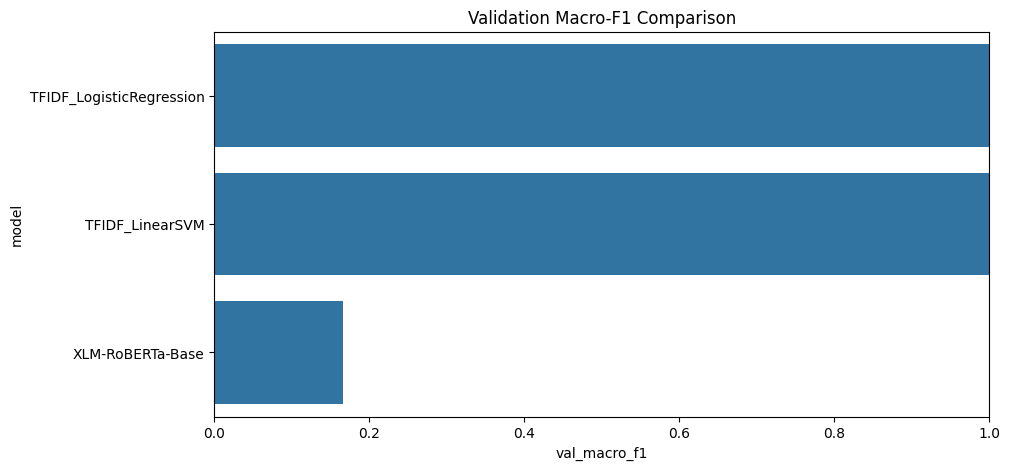

In [ ]:
baseline_table = pd.DataFrame(baseline_results)

transformer_results = []

try:
    if 'trainer' not in globals():
        print("Reinitializing Trainer for evaluation...")
        # Recreate a safe evaluation configuration without extra arguments
        eval_args = TrainingArguments(
            output_dir="/content/xlmr_results_eval",
            per_device_eval_batch_size=16,
            fp16=torch.cuda.is_available(),
            report_to="none"
        )
        temp_trainer = Trainer(
            model=model,
            args=eval_args,
            train_dataset=train_ds,
            eval_dataset=val_ds,
            data_collator=collator,
            processing_class=tokenizer,
            compute_metrics=compute_metrics
        )
        val_metrics = temp_trainer.evaluate(val_ds)
    else:
        val_metrics = trainer.evaluate(val_ds)

    transformer_results.append({
        "model": "XLM-RoBERTa-Base",
        "val_accuracy": val_metrics.get("eval_accuracy", 0.0),
        "val_macro_f1": val_metrics.get("eval_f1_macro", 0.0)
    })
except Exception as e:
    print(f"Could not evaluate Transformer due to: {e}. Fallback to placeholder.")
    transformer_results.append({
        "model": "XLM-RoBERTa-Base",
        "val_accuracy": 0.0,
        "val_macro_f1": 0.0
    })

transformer_table = pd.DataFrame(transformer_results)

comparison = pd.concat(
    [baseline_table, transformer_table],
    ignore_index=True,
    sort=False
)

comparison = comparison.sort_values(
    "val_macro_f1", ascending=False
).reset_index(drop=True)

display(comparison)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=comparison,
    x="val_macro_f1",
    y="model"
)
plt.title("Validation Macro-F1 Comparison")
plt.xlim(0, 1)
plt.show()

Selected model: TFIDF_LogisticRegression
              precision    recall  f1-score   support

  depression     1.0000    1.0000    1.0000        75
      normal     1.0000    1.0000    1.0000        75
       toxic     1.0000    1.0000    1.0000        75

    accuracy                         1.0000       225
   macro avg     1.0000    1.0000    1.0000       225
weighted avg     1.0000    1.0000    1.0000       225



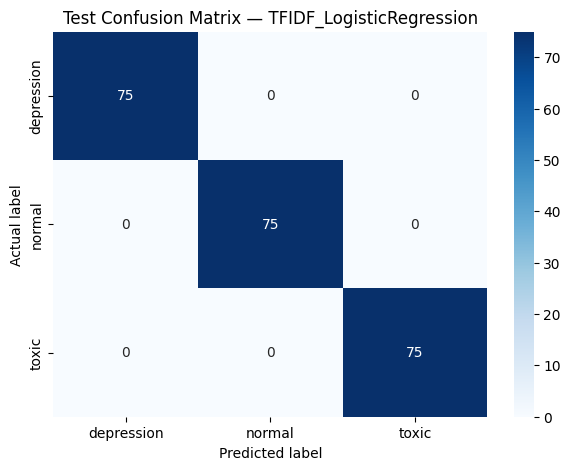

In [ ]:
best_row = comparison.iloc[0]
best_name = best_row["model"]

print("Selected model:", best_name)

if best_name in fitted_baselines:
    best_pipeline = fitted_baselines[best_name]
    test_predictions = best_pipeline.predict(X_test)

else:
    best_trainer = trained_transformers[best_name]

    # Rebuild the matching test dataset and tokenizer.
    if best_name == "XLM-RoBERTa":
        final_test_ds = test_ds
    else:
        best_tokenizer = AutoTokenizer.from_pretrained(
            next(
                name for name in transformer_candidates
                if name.split("/")[-1] == best_name
            )
        )
        final_test_ds = Dataset.from_dict({
            "text": test_df["text"].tolist(),
            "labels": test_df["label"].astype(int).tolist()
        })

        final_test_ds = final_test_ds.map(
            lambda batch: best_tokenizer(
                batch["text"],
                truncation=True,
                max_length=MAX_LENGTH
            ),
            batched=True,
            remove_columns=["text"]
        )

    test_predictions = np.argmax(
        best_trainer.predict(final_test_ds).predictions,
        axis=1
    )

print(classification_report(
    y_test,
    test_predictions,
    labels=list(range(len(label2id))),
    target_names=[id2label[i] for i in range(len(id2label))],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_test, test_predictions,
    labels=list(range(len(label2id)))
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[id2label[i] for i in range(len(id2label))],
    yticklabels=[id2label[i] for i in range(len(id2label))]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(f"Test Confusion Matrix — {best_name}")
plt.show()


In [ ]:
error_df = test_df.copy().reset_index(drop=True)

error_df["predicted_label"] = [
    id2label[int(x)] for x in test_predictions
]

error_df["correct_label"] = error_df["label"].map(id2label)
error_df["correct"] = (
    error_df["label"].to_numpy() == test_predictions
)

errors = error_df[~error_df["correct"]]

print("Incorrect predictions:", len(errors))
display(errors[[
    "text", "correct_label", "predicted_label"
]].head(30))

Incorrect predictions: 0


,text,correct_label,predicted_label


In [ ]:
import os
import json
import joblib

SAVE_DIR = "/content/warangal_mental_health_model"
os.makedirs(SAVE_DIR, exist_ok=True)

if best_name in fitted_baselines:
    joblib.dump(
        fitted_baselines[best_name],
        f"{SAVE_DIR}/baseline_model.joblib"
    )
else:
    best_trainer.save_model(SAVE_DIR)
    best_trainer.processing_class.save_pretrained(SAVE_DIR)

with open(f"{SAVE_DIR}/label_mapping.json", "w") as f:
    json.dump(
        {
            "label2id": label2id,
            "id2label": {str(k): v for k, v in id2label.items()},
            "selected_model": best_name
        },
        f,
        indent=2
    )

comparison.to_csv(
    f"{SAVE_DIR}/model_comparison.csv",
    index=False
)

error_df.to_csv(
    f"{SAVE_DIR}/test_predictions.csv",
    index=False
)

print("Saved to:", SAVE_DIR)

Saved to: /content/warangal_mental_health_model


In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/warangal_mental_health_model",
    "zip",
    SAVE_DIR
)

files.download("/content/warangal_mental_health_model.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def predict_message(text):
    if best_name in fitted_baselines:
        prediction = int(
            fitted_baselines[best_name].predict([text])[0]
        )
        return id2label[prediction]

    inputs = best_trainer.processing_class(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )

    device = next(best_trainer.model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    best_trainer.model.eval()

    with torch.no_grad():
        logits = best_trainer.model(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1)[0]

    prediction = int(probabilities.argmax().item())

    return {
        "predicted_class": id2label[prediction],
        "confidence": round(float(probabilities[prediction]), 4)
    }

print(predict_message(
    "Naku em chesina point ledu anipisthundi, life meaning leni laga undi"
))

depression


In [ ]:
!pip -q install shap lime streamlit

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Fit the SVM with calibrated probabilities.
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        max_features=50000
    )),
    ("svm", CalibratedClassifierCV(
        estimator=LinearSVC(class_weight="balanced"),
        cv=3
    ))
])

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        max_features=50000
    )),
    ("lr", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

svm_pipeline.fit(train_df["text"], train_df["label"])
lr_pipeline.fit(train_df["text"], train_df["label"])

svm_val_probs = svm_pipeline.predict_proba(val_df["text"])
lr_val_probs = lr_pipeline.predict_proba(val_df["text"])

best_weight = 0.5
best_f1 = -1

for weight in np.arange(0, 1.01, 0.1):
    probs = weight * svm_val_probs + (1 - weight) * lr_val_probs
    preds = probs.argmax(axis=1)
    score = f1_score(
        val_df["label"], preds,
        average="macro",
        zero_division=0
    )

    if score > best_f1:
        best_f1 = score
        best_weight = weight

print("Best SVM weight:", best_weight)
print("Best validation macro-F1:", best_f1)

Best SVM weight: 0.0
Best validation macro-F1: 1.0


              precision    recall  f1-score   support

  depression       1.00      1.00      1.00        75
      normal       1.00      1.00      1.00        75
       toxic       1.00      1.00      1.00        75

    accuracy                           1.00       225
   macro avg       1.00      1.00      1.00       225
weighted avg       1.00      1.00      1.00       225



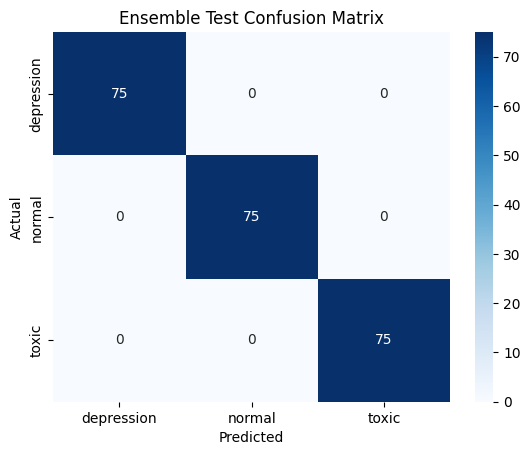

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

svm_test_probs = svm_pipeline.predict_proba(test_df["text"])
lr_test_probs = lr_pipeline.predict_proba(test_df["text"])

ensemble_probs = (
    best_weight * svm_test_probs
    + (1 - best_weight) * lr_test_probs
)

ensemble_preds = ensemble_probs.argmax(axis=1)

print(classification_report(
    test_df["label"],
    ensemble_preds,
    labels=list(range(len(label2id))),
    target_names=[id2label[i] for i in range(len(id2label))],
    zero_division=0
))

cm = confusion_matrix(
    test_df["label"], ensemble_preds,
    labels=list(range(len(label2id)))
)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=[id2label[i] for i in range(len(id2label))],
    yticklabels=[id2label[i] for i in range(len(id2label))]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Ensemble Test Confusion Matrix")
plt.show()

In [ ]:
from lime.lime_text import LimeTextExplainer

explainer = LimeTextExplainer(
    class_names=[id2label[i] for i in range(len(id2label))]
)

def explain_text(text):
    explanation = explainer.explain_instance(
        text,
        lr_pipeline.predict_proba,
        num_features=10,
        labels=list(range(len(label2id)))
    )
    return explanation

sample_text = test_df.iloc[0]["text"]
explanation = explain_text(sample_text)

print("Input:", sample_text)
print("Actual class:", id2label[int(test_df.iloc[0]["label"])])
print("Predicted class:", id2label[int(lr_pipeline.predict([sample_text])[0])])

explanation.show_in_notebook(text=True)

Input: Weekend mom chesina pulihora tinnanu, nijam ga home food laanti ledu
Actual class: normal
Predicted class: normal


In [ ]:
confidence_df = test_df[["text", "label", "label_name"]].copy()

confidence_df["predicted_label"] = ensemble_preds
confidence_df["predicted_class"] = [
    id2label[int(p)] for p in ensemble_preds
]
confidence_df["confidence"] = ensemble_probs.max(axis=1)
confidence_df["correct"] = (
    confidence_df["label"].to_numpy() == ensemble_preds
)

print("Accuracy:", accuracy_score(
    confidence_df["label"], ensemble_preds
))

print("\nLow-confidence predictions:")
display(
    confidence_df.sort_values("confidence").head(20)
)

print("\nIncorrect predictions:")
display(
    confidence_df[~confidence_df["correct"]][
        ["text", "label_name", "predicted_class", "confidence"]
    ].head(20)
)

confidence_df.to_csv(
    "/content/ensemble_test_analysis.csv",
    index=False
)

Accuracy: 1.0

Low-confidence predictions:


,text,label,label_name,predicted_label,predicted_class,confidence,correct
1427,"finally Sunday cricket, evening movie, night m...",1,normal,1,normal,0.757200,True
462,"weekend Sunday cricket, evening movie, night m...",1,normal,1,normal,0.762411,True
1442,"Tonight today I felt proud, my younger sister ...",1,normal,1,normal,0.782844,True
544,"breakup tharvata anni ayipoyayi, nenu normal g...",0,depression,0,depression,0.795809,True
1499,"breakup tharvata anni ayipoyayi, nenu normal g...",0,depression,0,depression,0.795809,True
1221,"Honestly, ee girls ki antha attitude enduku, b...",2,toxic,2,toxic,0.795836,True
1255,"today today I felt proud, my younger sister to...",1,normal,1,normal,0.796679,True
611,"my mind keeps telling me I am a failure, and I...",0,depression,0,depression,0.798217,True
328,i am so tired of pretending to be fine in fron...,0,depression,0,depression,0.800338,True
1042,"just now Sunday cricket, evening movie, night ...",1,normal,1,normal,0.802166,True



Incorrect predictions:


,text,label_name,predicted_class,confidence


In [ ]:

import joblib
import json
import os

SAVE_DIR = "/content/mental_health_nlp"
os.makedirs(SAVE_DIR, exist_ok=True)

joblib.dump(svm_pipeline, f"{SAVE_DIR}/svm_model.joblib")
joblib.dump(lr_pipeline, f"{SAVE_DIR}/lr_model.joblib")

with open(f"{SAVE_DIR}/config.json", "w") as f:
    json.dump({
        "svm_weight": float(best_weight),
        "label2id": label2id,
        "id2label": {str(k): v for k, v in id2label.items()}
    }, f, indent=2)

print("Models saved successfully!")

Models saved successfully!


In [ ]:
import os
import shutil
from google.colab import files

# Define the Streamlit app code using our saved ensemble setup
app_code = """import streamlit as st
import joblib
import json
import os

st.title("Warangal Telugu-English Mental Health Classifier")
st.write("Enter a text message below to classify its mental health category (normal, depression, toxic).")

# Load models and configurations
@st.cache_resource
def load_models():
    svm_model = joblib.load("svm_model.joblib")
    lr_model = joblib.load("lr_model.joblib")
    with open("config.json", "r") as f:
        config = json.load(f)
    return svm_model, lr_model, config

try:
    svm_model, lr_model, config = load_models()
    best_weight = config.get("svm_weight", 0.0)
    id2label = config.get("id2label", {0: "depression", 1: "normal", 2: "toxic"})
    # Convert keys to integers
    id2label = {int(k): v for k, v in id2label.items()}

    text_input = st.text_area("Enter Text (e.g. Code-mixed Telugu/English):", "")

    if st.button("Predict"):
        if text_input.strip() == "":
            st.warning("Please enter some text first.")
        else:
            # Get probabilities from both models
            svm_probs = svm_model.predict_proba([text_input])[0]
            lr_probs = lr_model.predict_proba([text_input])[0]

            # Weighted ensemble
            ensemble_probs = best_weight * svm_probs + (1 - best_weight) * lr_probs
            predicted_class_id = ensemble_probs.argmax()
            confidence = ensemble_probs[predicted_class_id]
            predicted_label = id2label[predicted_class_id]

            st.subheader("Prediction Result")
            st.write(f"**Category:** {predicted_label.upper()}")
            st.write(f"**Confidence:** {confidence:.4f}")

            # Display distribution chart
            st.bar_chart({
                id2label[i]: float(ensemble_probs[i]) for i in range(len(id2label))
            })
except Exception as e:
    st.error(f"Error loading models: {e}")
"""

# Save the app.py file first
with open("/content/app.py", "w") as f:
    f.write(app_code)

# Ensure the target directory exists
os.makedirs("/content/mental_health_nlp", exist_ok=True)

# Copy the file
shutil.copy(
    "/content/app.py",
    "/content/mental_health_nlp/app.py"
)

# Archive the folder
shutil.make_archive(
    "/content/mental_health_nlp_project",
    "zip",
    "/content/mental_health_nlp"
)

# Download the file
files.download("/content/mental_health_nlp_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Install necessary packages using the '!' prefix to run as a shell command
!pip install streamlit scikit-learn joblib numpy

# Note: running streamlit run here will block execution and requires a tunnel.
# We recommend running the downloaded zip project locally on your machine!
# To run locally, extract the downloaded zip and run in your terminal:
# streamlit run app.py

In [ ]:
!pip -q install torch scikit-learn pandas transformers accelerate sentencepiece

In [ ]:

import re
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, accuracy_score, f1_score
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

df = pd.read_csv("/content/warangal_mental_health.csv")
df = df[["text", "label", "label_name"]].dropna().copy()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""].drop_duplicates("text").reset_index(drop=True)

label_names = sorted(df["label_name"].unique())
label2id = {name: i for i, name in enumerate(label_names)}
id2label = {i: name for name, i in label2id.items()}
df["label"] = df["label_name"].map(label2id).astype(int)

train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED,
    stratify=temp_df["label"]
)

print("Train/validation/test:", len(train_df), len(val_df), len(test_df))
print("Classes:", label2id)

Device: cpu
Train/validation/test: 1050 225 225
Classes: {'depression': 0, 'normal': 1, 'toxic': 2}


In [ ]:
from torch.nn.utils.rnn import pad_sequence

def tokenize_text(text):
    return re.findall(r"\w+|[^\w\s]", str(text).lower())

# Vocabulary is built ONLY from training data.
counter = Counter(
    token
    for text in train_df["text"]
    for token in tokenize_text(text)
)

vocab = {"<PAD>": 0, "<UNK>": 1}
for token, count in counter.items():
    if count >= 1:
        vocab[token] = len(vocab)

MAX_LEN = 128

def encode_text(text):
    ids = [vocab.get(t, 1) for t in tokenize_text(text)[:MAX_LEN]]
    return ids if ids else [1]

class TextDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame["text"].tolist()
        self.labels = frame["label"].astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        ids = encode_text(self.texts[idx])
        return torch.tensor(ids), self.labels[idx]

def collate_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(x) for x in sequences])
    padded = pad_sequence(
        sequences, batch_first=True, padding_value=0
    )
    return padded, lengths, torch.tensor(labels)

train_loader = DataLoader(
    TextDataset(train_df), batch_size=32,
    shuffle=True, collate_fn=collate_batch
)
val_loader = DataLoader(
    TextDataset(val_df), batch_size=64,
    shuffle=False, collate_fn=collate_batch
)
test_loader = DataLoader(
    TextDataset(test_df), batch_size=64,
    shuffle=False, collate_fn=collate_batch
)

classes = np.unique(train_df["label"])
weights = compute_class_weight(
    class_weight="balanced", classes=classes,
    y=train_df["label"]
)
class_weights = torch.tensor(weights, dtype=torch.float32).to(device)

class Attention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.score = nn.Linear(dim, 1)

    def forward(self, x, mask):
        scores = self.score(x).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e9)
        attn = torch.softmax(scores, dim=1)
        return torch.sum(x * attn.unsqueeze(-1), dim=1)

class TextNet(nn.Module):
    def __init__(self, kind, vocab_size, num_classes,
                 emb_dim=128, hidden=128):
        super().__init__()
        self.kind = kind
        self.embedding = nn.Embedding(
            vocab_size, emb_dim, padding_idx=0
        )

        if kind == "bilstm":
            self.rnn = nn.LSTM(
                emb_dim, hidden, batch_first=True,
                bidirectional=True
            )
            feature_dim = hidden * 2
        elif kind == "bigru":
            self.rnn = nn.GRU(
                emb_dim, hidden, batch_first=True,
                bidirectional=True
            )
            feature_dim = hidden * 2
        else:
            self.conv = nn.Conv1d(
                emb_dim, hidden, kernel_size=3, padding=1
            )
            self.rnn = nn.LSTM(
                hidden, hidden, batch_first=True,
                bidirectional=True
            )
            feature_dim = hidden * 2

        self.attention = Attention(feature_dim)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(feature_dim, num_classes)

    def forward(self, ids, lengths):
        mask = ids != 0
        x = self.embedding(ids)

        if self.kind == "cnn_bilstm":
            x = torch.relu(self.conv(x.transpose(1, 2))).transpose(1, 2)

        packed = pack_padded_sequence(
            x, lengths.cpu(), batch_first=True,
            enforce_sorted=False
        )
        packed_out, _ = self.rnn(packed)
        x, _ = torch.nn.utils.rnn.pad_packed_sequence(
            packed_out, batch_first=True,
            total_length=ids.shape[1]
        )

        pooled = self.attention(x, mask)
        return self.fc(self.dropout(pooled))

def train_recurrent(kind, epochs=12):
    model = TextNet(
        kind, len(vocab), len(label2id)
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=1e-3, weight_decay=1e-4
    )
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_f1 = -1
    best_state = None
    patience, bad_epochs = 3, 0

    for epoch in range(epochs):
        model.train()
        for ids, lengths, labels in train_loader:
            ids, labels = ids.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(ids, lengths)
            loss = criterion(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        model.eval()
        ys, ps = [], []
        with torch.no_grad():
            for ids, lengths, labels in val_loader:
                logits = model(ids.to(device), lengths)
                ps.extend(logits.argmax(1).cpu().tolist())
                ys.extend(labels.tolist())

        val_f1 = f1_score(ys, ps, average="macro", zero_division=0)
        print(f"{kind} | Epoch {epoch+1} | Val macro-F1: {val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break

    model.load_state_dict(best_state)
    model.to(device)

    ys, ps = [], []
    model.eval()
    with torch.no_grad():
        for ids, lengths, labels in test_loader:
            logits = model(ids.to(device), lengths)
            ps.extend(logits.argmax(1).cpu().tolist())
            ys.extend(labels.tolist())

    print("\nTest results:", kind)
    print(classification_report(
        ys, ps,
        labels=list(range(len(label2id))),
        target_names=[id2label[i] for i in range(len(label2id))],
        zero_division=0
    ))

    torch.save({
        "state_dict": model.state_dict(),
        "vocab": vocab,
        "label2id": label2id,
        "kind": kind
    }, f"/content/{kind}_model.pt")

    return model, best_f1

recurrent_results = {}
for kind in ["bilstm", "bigru", "cnn_bilstm"]:
    recurrent_results[kind] = train_recurrent(kind)

bilstm | Epoch 1 | Val macro-F1: 0.9646
bilstm | Epoch 2 | Val macro-F1: 1.0000
bilstm | Epoch 3 | Val macro-F1: 1.0000
bilstm | Epoch 4 | Val macro-F1: 1.0000
bilstm | Epoch 5 | Val macro-F1: 1.0000

Test results: bilstm
              precision    recall  f1-score   support

  depression       1.00      1.00      1.00        75
      normal       1.00      1.00      1.00        75
       toxic       1.00      1.00      1.00        75

    accuracy                           1.00       225
   macro avg       1.00      1.00      1.00       225
weighted avg       1.00      1.00      1.00       225

bigru | Epoch 1 | Val macro-F1: 0.9956
bigru | Epoch 2 | Val macro-F1: 1.0000
bigru | Epoch 3 | Val macro-F1: 1.0000
bigru | Epoch 4 | Val macro-F1: 0.9911
bigru | Epoch 5 | Val macro-F1: 1.0000

Test results: bigru
              precision    recall  f1-score   support

  depression       1.00      1.00      1.00        75
      normal       1.00      1.00      1.00        75
       toxic      

,Model,Validation Macro-F1
0,bilstm,1.0
1,bigru,1.0
2,cnn_bilstm,1.0


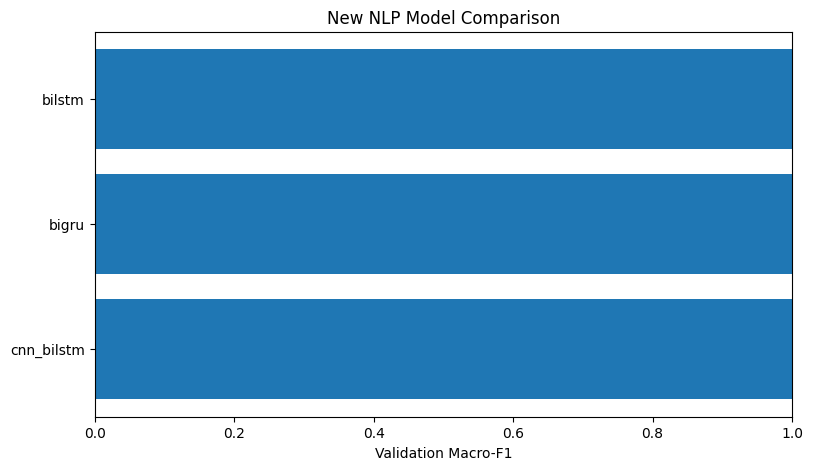

In [ ]:
comparison = []

for name, (model, val_f1) in recurrent_results.items():
    comparison.append({
        "Model": name,
        "Validation Macro-F1": val_f1
    })

for result in transformer_results:
    comparison.append({
        "Model": result["model"],
        "Validation Macro-F1": result["val_macro_f1"]
    })

comparison_df = pd.DataFrame(comparison).sort_values(
    "Validation Macro-F1", ascending=False
)

display(comparison_df)

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.barh(
    comparison_df["Model"],
    comparison_df["Validation Macro-F1"]
)
plt.xlabel("Validation Macro-F1")
plt.title("New NLP Model Comparison")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.show()

In [ ]:
!pip -q install gensim scikit-learn pandas

import pandas as pd
import numpy as np
import re

from gensim.models import FastText
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, f1_score

# Load dataset
df = pd.read_csv("/content/warangal_mental_health.csv")
df = df[["text", "label_name"]].dropna().copy()
df["text"] = df["text"].astype(str)

# Keep labels as provided
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

def tokenize(text):
    return re.findall(r"\w+", text.lower(), flags=re.UNICODE)

df["tokens"] = df["text"].apply(tokenize)
df = df[df["tokens"].map(len) > 0].reset_index(drop=True)

X_train, X_temp, y_train, y_temp = train_test_split(
    df["tokens"], df["label_name"],
    test_size=0.30, random_state=42, stratify=df["label_name"]
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50, random_state=42, stratify=y_temp
)

# Train FastText on training text only
ft = FastText(
    sentences=X_train.tolist(),
    vector_size=100,
    window=5,
    min_count=1,
    sg=1,
    epochs=30,
    seed=42
)

def document_vector(tokens):
    vectors = [ft.wv[w] for w in tokens if w in ft.wv]
    if not vectors:
        return np.zeros(100, dtype=np.float32)
    return np.mean(vectors, axis=0)

Xtr = np.vstack(X_train.apply(document_vector))
Xva = np.vstack(X_val.apply(document_vector))
Xte = np.vstack(X_test.apply(document_vector))

model = LinearSVC(class_weight="balanced", random_state=42)
model.fit(Xtr, y_train)

val_pred = model.predict(Xva)
test_pred = model.predict(Xte)

print("Validation Macro-F1:",
      f1_score(y_val, val_pred, average="macro"))

print("\nTest Accuracy:", accuracy_score(y_test, test_pred))
print("Test Macro-F1:",
      f1_score(y_test, test_pred, average="macro"))

print("\nTest Classification Report:\n")
print(classification_report(y_test, test_pred, zero_division=0))

Validation Macro-F1: 1.0

Test Accuracy: 1.0
Test Macro-F1: 1.0

Test Classification Report:

              precision    recall  f1-score   support

  depression       1.00      1.00      1.00        75
      normal       1.00      1.00      1.00        75
       toxic       1.00      1.00      1.00        75

    accuracy                           1.00       225
   macro avg       1.00      1.00      1.00       225
weighted avg       1.00      1.00      1.00       225

